# Exercise 1.7

# Importing Libraries

In [2]:
# import libraries
import pandas as pd
import numpy as np
import networkx as nx
import os
import matplotlib.pyplot as plt
from pyvis.network import Network
import seaborn as sns
import pyvis

In [3]:
# import relationship data
df_relationship = pd.read_csv('country_relationship.csv', index_col = 0)

In [4]:
df_relationship

,source,target,value
0,Austria,France,6
1,Austria,Russia,5
2,Germany,Italy,22
3,Austria,Germany,9
4,Germany,Spain,3
...,...,...,...
85,Greece,Italy,3
86,Italy,Japan,6
87,Australia,Philippines,3
88,Romania,Russia,6


In [5]:
# creating graph from a pandas dataframe
G = nx.from_pandas_edgelist(df_relationship, 
                            source = "source", 
                            target = "target", 
                            edge_attr = "value", 
                            create_using = nx.Graph())

# NetworkX Visualization

In [6]:
import psutil
print(f"Memory used: {psutil.virtual_memory().percent}%")

Memory used: 63.5%


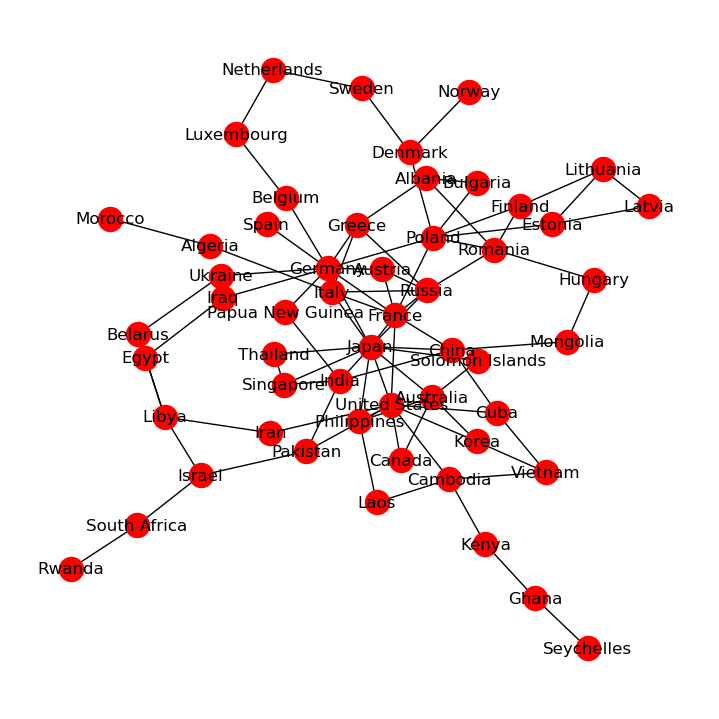

In [7]:
h = plt.figure(figsize = (7,7))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, with_labels = True, node_color = 'red', edge_cmap = plt.cm.Blues, pos = pos)
plt.show() 

In [8]:
# save figure
h.savefig('networkx_plt_countries.png')

# Pyvis Visualization

In [14]:
# define net object
net = Network()
net = Network(notebook = True,width="900px", height="800px", bgcolor='#178236', font_color='orange')

# define nodes from the G object
node_degree = dict(G.degree)

# setting up node size attributes
nx.set_node_attributes(G, node_degree, 'size')
net.from_nx(G)
net.show_buttons(filter_ = True)
net.repulsion()
net.show("countries.html")

countries.html


# Leiden Algorithm

In [17]:
from cdlib import algorithms
coms = algorithms.leiden(G)

In [18]:
type(coms)

cdlib.classes.node_clustering.NodeClustering

In [19]:
new_com = coms.to_node_community_map()

In [20]:
new_com

defaultdict(list,
            {'Philippines': [0],
             'Australia': [0],
             'United States': [0],
             'Laos': [0],
             'Cambodia': [0],
             'Kenya': [0],
             'Ghana': [0],
             'Seychelles': [0],
             'Cuba': [0],
             'Canada': [0],
             'Korea': [0],
             'Vietnam': [0],
             'Ukraine': [1],
             'Belarus': [1],
             'Libya': [1],
             'Egypt': [1],
             'Iraq': [1],
             'Pakistan': [1],
             'Israel': [1],
             'South Africa': [1],
             'Iran': [1],
             'Rwanda': [1],
             'Poland': [2],
             'Estonia': [2],
             'Latvia': [2],
             'Lithuania': [2],
             'Finland': [2],
             'Albania': [2],
             'Romania': [2],
             'Bulgaria': [2],
             'Hungary': [2],
             'Mongolia': [2],
             'Austria': [3],
             'France': [3]

In [21]:
# put the output from new_com into a dictionary
dict_com = {k:v[0] for k,v in new_com.items()}

In [22]:
dict_com

{'Philippines': 0,
 'Australia': 0,
 'United States': 0,
 'Laos': 0,
 'Cambodia': 0,
 'Kenya': 0,
 'Ghana': 0,
 'Seychelles': 0,
 'Cuba': 0,
 'Canada': 0,
 'Korea': 0,
 'Vietnam': 0,
 'Ukraine': 1,
 'Belarus': 1,
 'Libya': 1,
 'Egypt': 1,
 'Iraq': 1,
 'Pakistan': 1,
 'Israel': 1,
 'South Africa': 1,
 'Iran': 1,
 'Rwanda': 1,
 'Poland': 2,
 'Estonia': 2,
 'Latvia': 2,
 'Lithuania': 2,
 'Finland': 2,
 'Albania': 2,
 'Romania': 2,
 'Bulgaria': 2,
 'Hungary': 2,
 'Mongolia': 2,
 'Austria': 3,
 'France': 3,
 'Russia': 3,
 'Germany': 3,
 'Italy': 3,
 'Spain': 3,
 'Greece': 3,
 'Algeria': 3,
 'Morocco': 3,
 'Japan': 4,
 'China': 4,
 'Thailand': 4,
 'Singapore': 4,
 'Solomon Islands': 4,
 'India': 4,
 'Papua New Guinea': 4,
 'Denmark': 5,
 'Norway': 5,
 'Sweden': 5,
 'Netherlands': 5,
 'Luxembourg': 5,
 'Belgium': 5}

In [25]:
# rerun network graph with communities as an argument
nx.set_node_attributes(G, dict_com, 'group')
com_net = Network(notebook = True, width="1300px", height="700px", bgcolor='#222222', font_color='white')
com_net.from_nx(G)
com_net.show_buttons(filter_ = True)
com_net.repulsion()
com_net.write_html("countries_communities_leiden.html")
com_net.show("countries_communities_leiden.html")

countries_communities_leiden.html


#### These relationships seem to be by geographical locations rather than related to conflict between countries. Purple and blue seem to be the same. The connection between the countries are more gergraphical

# 8

In [26]:
# degree centrality
degree_dict = nx.degree_centrality(G)
degree_dict

{'Austria': 0.05660377358490566,
 'France': 0.1509433962264151,
 'Russia': 0.11320754716981132,
 'Germany': 0.20754716981132074,
 'Italy': 0.11320754716981132,
 'Spain': 0.018867924528301886,
 'Poland': 0.1320754716981132,
 'Estonia': 0.05660377358490566,
 'Latvia': 0.03773584905660377,
 'Lithuania': 0.05660377358490566,
 'Finland': 0.05660377358490566,
 'Denmark': 0.05660377358490566,
 'Norway': 0.018867924528301886,
 'Sweden': 0.03773584905660377,
 'Netherlands': 0.03773584905660377,
 'Luxembourg': 0.03773584905660377,
 'Belgium': 0.03773584905660377,
 'Greece': 0.07547169811320754,
 'Albania': 0.05660377358490566,
 'Ukraine': 0.03773584905660377,
 'Belarus': 0.03773584905660377,
 'Libya': 0.07547169811320754,
 'Egypt': 0.03773584905660377,
 'Iraq': 0.03773584905660377,
 'Japan': 0.22641509433962265,
 'Algeria': 0.03773584905660377,
 'Morocco': 0.018867924528301886,
 'China': 0.09433962264150943,
 'Thailand': 0.03773584905660377,
 'Singapore': 0.05660377358490566,
 'Philippines': 0.0

In [27]:
df_degree = pd.DataFrame(degree_dict.items(), columns=['countries','centrality'])

In [28]:
df_degree.sort_values(by = ['centrality'], ascending=False, inplace = True)

In [29]:
df_degree

,countries,centrality
24,Japan,0.226415
3,Germany,0.207547
34,United States,0.169811
1,France,0.150943
6,Poland,0.132075
4,Italy,0.113208
2,Russia,0.113208
31,Australia,0.094340
27,China,0.094340
33,India,0.094340


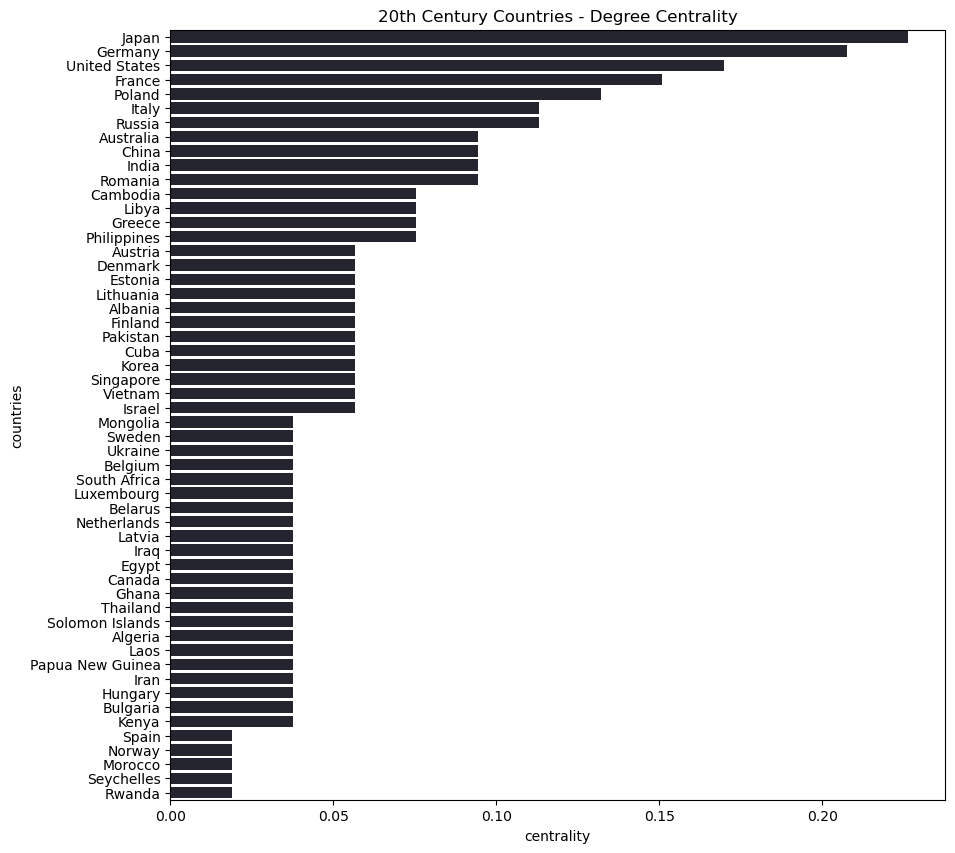

In [30]:
# plot the degree centrality
plt.figure(figsize = (10, 10))
with sns.dark_palette("xkcd:blue", 22):
    sns.barplot(x = "centrality", y = "countries",
    saturation = 0.9, data = df_degree).set_title("20th Century Countries - Degree Centrality")

In [31]:
# closeness centrality
closeness_dict = nx.closeness_centrality(G)
df_closeness = pd.DataFrame(closeness_dict.items(), columns=['countries','centrality'])

In [32]:
df_closeness.sort_values(by = ['centrality'], ascending=False, inplace = True)

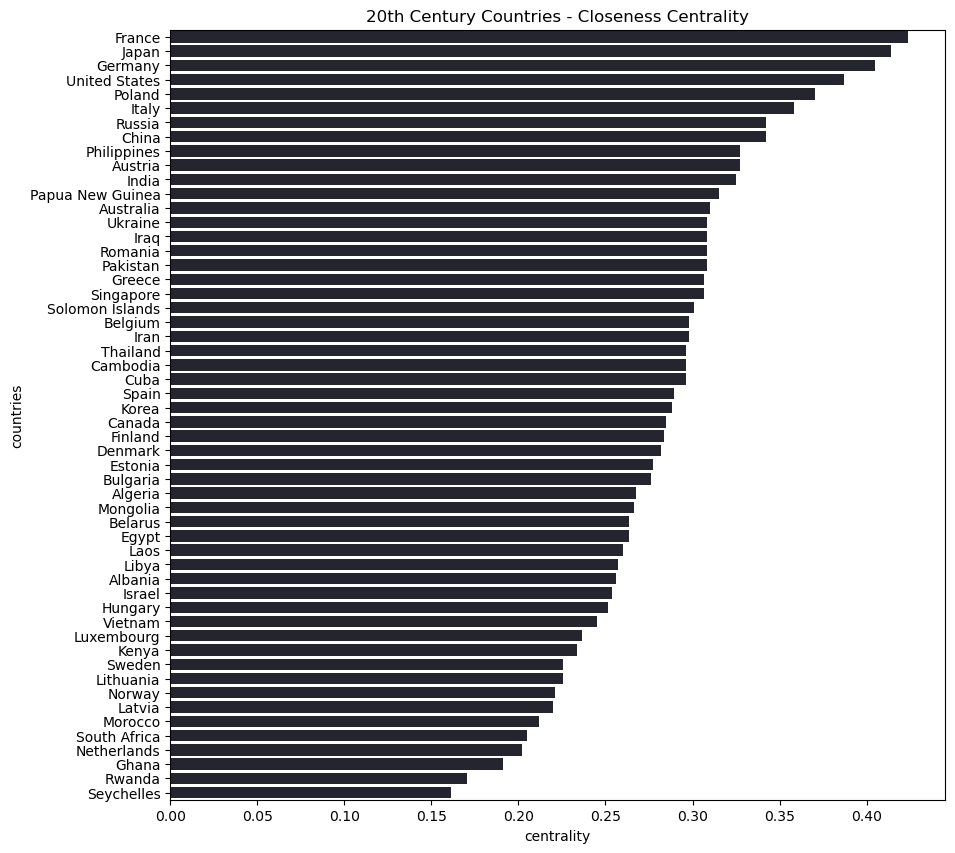

In [33]:
plt.figure(figsize = (10, 10))
with sns.dark_palette("xkcd:blue", 22):
    sns.barplot(x = "centrality", y = "countries",
    saturation = 0.9, data = df_closeness).set_title("20th Century Countries - Closeness Centrality")

In [34]:
# betweenness centrality
betweenness_dict = nx.betweenness_centrality(G)
df_betweennes = pd.DataFrame(betweenness_dict.items(), columns=['countries','centrality'])

In [35]:
df_betweennes.sort_values(by = ['centrality'], ascending=False, inplace = True)

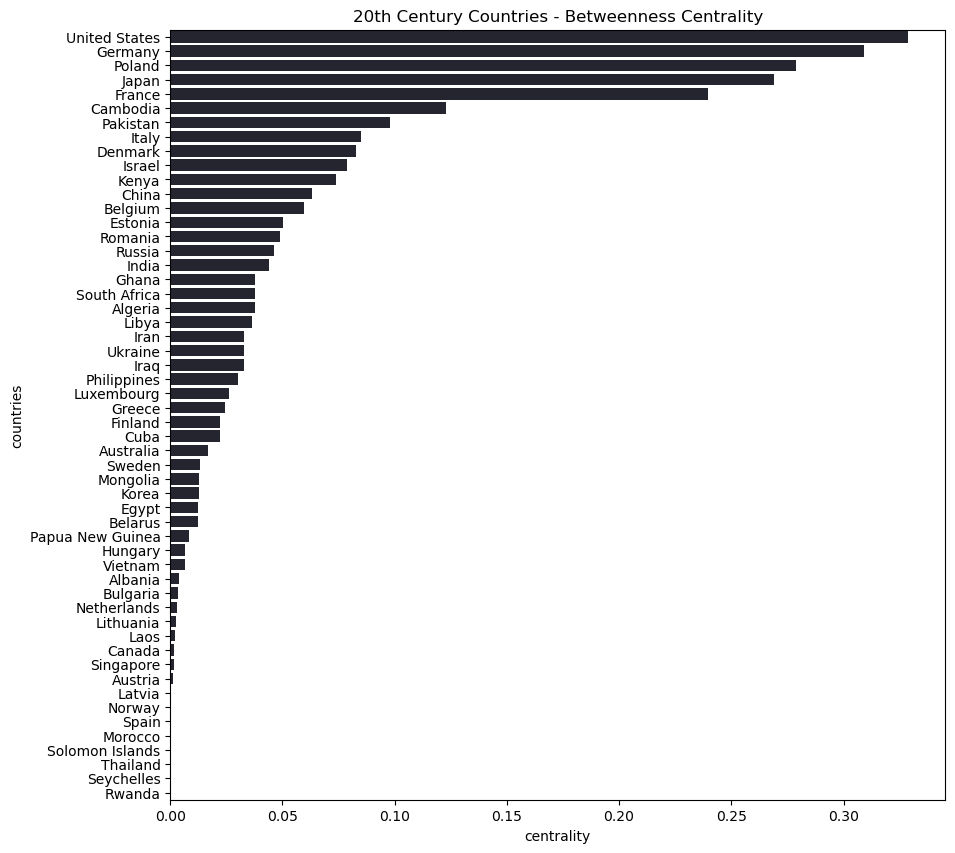

In [36]:
plt.figure(figsize = (10, 10))
with sns.dark_palette("xkcd:blue", 22):
    sns.barplot(x = "centrality", y = "countries",
    saturation = 0.9, data = df_betweennes).set_title("20th Century Countries - Betweenness Centrality")

#### the centrality measures match with historical reality. Germany, Japan, and the United States consistently appear at the top, showing their roles in these wars. In contrast, countries that experienced relative peace or were involved in internal conflicts rank lower.

In [37]:
# save centrality measures
nx.set_node_attributes(G, degree_dict, 'degree_centrality')
nx.set_node_attributes(G, betweenness_dict, 'betweenness_centrality')
nx.set_node_attributes(G, closeness_dict, 'closeness_centrality')

In [38]:
# view all nodes with their attributes
G.nodes(data=True)  

NodeDataView({'Austria': {'size': 3, 'group': 3, 'degree_centrality': 0.05660377358490566, 'betweenness_centrality': 0.0013857211970419521, 'closeness_centrality': 0.3271604938271605}, 'France': {'size': 8, 'group': 3, 'degree_centrality': 0.1509433962264151, 'betweenness_centrality': 0.23955224675151254, 'closeness_centrality': 0.424}, 'Russia': {'size': 6, 'group': 3, 'degree_centrality': 0.11320754716981132, 'betweenness_centrality': 0.04608490535238594, 'closeness_centrality': 0.3419354838709677}, 'Germany': {'size': 11, 'group': 3, 'degree_centrality': 0.20754716981132074, 'betweenness_centrality': 0.3092614764026871, 'closeness_centrality': 0.40458015267175573}, 'Italy': {'size': 6, 'group': 3, 'degree_centrality': 0.11320754716981132, 'betweenness_centrality': 0.08478940593258019, 'closeness_centrality': 0.3581081081081081}, 'Spain': {'size': 1, 'group': 3, 'degree_centrality': 0.018867924528301886, 'betweenness_centrality': 0.0, 'closeness_centrality': 0.2896174863387978}, 'Pol

# The findings provide only a broad overview of interactions, and the dataset would require substantial refinement before being suitable for professional use because it is scraped from a website and the margin for error is still existent as one country could normally be mentioned multiple times even if it had little to no involvement.